In [1]:
! pip install nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 5.4 MB/s  0:00:00 eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import nltk
import string
import random

In [ ]:

# import nltk

from nltk.corpus import stopwords, brsown
from nltk import FreqDist
from nltk import ngrams



nltk.download('stopwords')
nltk.download('punkt')
nltk.download('brown')

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/shubhamkeshari/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to
[nltk_data]     /Users/shubhamkeshari/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/shubhamkeshari/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package brown to
[nltk_data]     /Users/shubhamkeshari/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.


True

In [5]:
stopwords = nltk.corpus.stopwords.words('english')
print(stopwords)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

In [6]:
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [7]:
# removal list
removal_list = stopwords + list(string.punctuation)

print(removal_list)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

### Loading the sentences via ngrams

In [8]:
sentences = brown.sents()
for i in sentences[:3]:
   print(i)

['The', 'Fulton', 'County', 'Grand', 'Jury', 'said', 'Friday', 'an', 'investigation', 'of', "Atlanta's", 'recent', 'primary', 'election', 'produced', '``', 'no', 'evidence', "''", 'that', 'any', 'irregularities', 'took', 'place', '.']
['The', 'jury', 'further', 'said', 'in', 'term-end', 'presentments', 'that', 'the', 'City', 'Executive', 'Committee', ',', 'which', 'had', 'over-all', 'charge', 'of', 'the', 'election', ',', '``', 'deserves', 'the', 'praise', 'and', 'thanks', 'of', 'the', 'City', 'of', 'Atlanta', "''", 'for', 'the', 'manner', 'in', 'which', 'the', 'election', 'was', 'conducted', '.']
['The', 'September-October', 'term', 'jury', 'had', 'been', 'charged', 'by', 'Fulton', 'Superior', 'Court', 'Judge', 'Durwood', 'Pye', 'to', 'investigate', 'reports', 'of', 'possible', '``', 'irregularities', "''", 'in', 'the', 'hard-fought', 'primary', 'which', 'was', 'won', 'by', 'Mayor-nominate', 'Ivan', 'Allen', 'Jr.', '.']


In [9]:
unigram = []
bigram = []
trigram = []

In [10]:
# filtering
for i in sentences:

  i = [word.lower() for word in i if word.lower() not in removal_list]
  unigram.extend(i)
  bigram.extend(list(ngrams(i, 2, pad_left=True, pad_right=True)))
  trigram.extend(list(ngrams(i, 3, pad_left=True, pad_right=True)))

In [11]:
unigram[:20]

['fulton',
 'county',
 'grand',
 'jury',
 'said',
 'friday',
 'investigation',
 "atlanta's",
 'recent',
 'primary',
 'election',
 'produced',
 '``',
 'evidence',
 "''",
 'irregularities',
 'took',
 'place',
 'jury',
 'said']

In [12]:
bigram[:25]

[(None, 'fulton'),
 ('fulton', 'county'),
 ('county', 'grand'),
 ('grand', 'jury'),
 ('jury', 'said'),
 ('said', 'friday'),
 ('friday', 'investigation'),
 ('investigation', "atlanta's"),
 ("atlanta's", 'recent'),
 ('recent', 'primary'),
 ('primary', 'election'),
 ('election', 'produced'),
 ('produced', '``'),
 ('``', 'evidence'),
 ('evidence', "''"),
 ("''", 'irregularities'),
 ('irregularities', 'took'),
 ('took', 'place'),
 ('place', None),
 (None, 'jury'),
 ('jury', 'said'),
 ('said', 'term-end'),
 ('term-end', 'presentments'),
 ('presentments', 'city'),
 ('city', 'executive')]

In [13]:
bigram[:-2:-1]

[('stupefying', None)]

In [14]:
trigram[:5]

[(None, None, 'fulton'),
 (None, 'fulton', 'county'),
 ('fulton', 'county', 'grand'),
 ('county', 'grand', 'jury'),
 ('grand', 'jury', 'said')]

In [15]:
# frequency
fdist_unigram = FreqDist(unigram)
fdist_bigram = FreqDist(bigram)
fdist_trigram = FreqDist(trigram)

# Most freuent (top 10)
print(fdist_unigram.most_common(10))
print(fdist_bigram.most_common(10))
print(fdist_trigram.most_common(10))

[('``', 8837), ("''", 8789), ('--', 3432), ('one', 3292), ('would', 2714), ('said', 1961), ('new', 1635), ('could', 1601), ('time', 1598), ('two', 1412)]
[(("''", None), 4757), ((None, '``'), 4318), ((None, 'one'), 728), (("''", 'said'), 484), (('said', None), 463), (('united', 'states'), 392), ((None, 'would'), 364), (('said', '``'), 361), ((None, 'first'), 330), ((None, None), 301)]
[(("''", None, None), 4757), ((None, None, '``'), 4318), ((None, None, 'one'), 728), ((None, None, None), 602), (('said', None, None), 463), ((None, None, 'would'), 364), ((None, None, 'first'), 330), ((None, None, 'even'), 299), ((None, None, 'mr.'), 269), ((None, None, '--'), 248)]


In [16]:
# Dictionary Counter
from collections import Counter, defaultdict

d = defaultdict(Counter)

for ngram, count in fdist_trigram.items():
  if None not in ngram:

    prefix = ngram[:-1]
    suffix = ngram[-1]

    d[prefix][suffix] += count

In [17]:
d

defaultdict(collections.Counter,
            {('fulton',
              'county'): Counter({'grand': 1,
                      'purchasing': 1,
                      'general': 1,
                      'receives': 1,
                      'receive': 1,
                      'jail': 1}),
             ('county', 'grand'): Counter({'jury': 1}),
             ('grand',
              'jury'): Counter({'said': 1,
                      'commented': 1,
                      'took': 1,
                      'subpenas': 1,
                      'room': 1,
                      'indictments': 1,
                      'called': 1,
                      'investigation': 1}),
             ('jury',
              'said'): Counter({'``': 2,
                      'friday': 1,
                      'term-end': 1,
                      'find': 1,
                      'believes': 1,
                      'state': 1,
                      'found': 1}),
             ('said',
              'friday'): Counter({'

## SpaCy

In [18]:
! pip install spacy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 1.5 MB/s  0:00:04 eta 0:00:010m
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 690.4/690.4 kB 2.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 833.8/833.8 kB 3.2 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 3.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [spacy]m14/15 [spacy]]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [19]:
# model - english
! spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 3.8 MB/s  0:00:03 eta 0:00:01

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [20]:
import spacy
nlp = spacy.load('en_core_web_sm')

In [22]:
text = """
NLTK is a leading platform for building Python programs to work with human language data. It provides easy-to-use interfaces to over 50 corpora and lexical resources such as WordNet, along with a suite of text processing libraries for classification, tokenization, stemming, tagging, parsing, and semantic reasoning, wrappers for industrial-strength NLP libraries, and an active discussion forum.

Thanks to a hands-on guide introducing programming fundamentals alongside topics in computational linguistics, plus comprehensive API documentation, NLTK is suitable for linguists, engineers, students, educators, researchers, and industry users alike. NLTK is available for Windows, macOS, and Linux. Best of all, NLTK is a free, open source, community-driven project.

NLTK has been called “a wonderful tool for teaching, and working in, computational linguistics using Python,” and “an amazing library to play with natural language.”

Natural Language Processing with Python provides a practical introduction to programming for language processing. Written by the creators of NLTK, it guides the reader through the fundamentals of writing Python programs, working with corpora, categorizing text, analyzing linguistic structure, and more. The online version of the book has been been updated for Python 3 and NLTK 3. (The original Python 2 version is still available at https://www.nltk.org/book_1ed.)
"""

In [23]:
# Text data loaded to the spacy model
doc = nlp(text)

In [24]:
# Tokenization
for token in doc[:5]:
  print(token)



NLTK
is
a
leading


In [ ]:
# other attributes
for token in doc[:16]:
    print(f"{token.text:<15} {token.pos_:<10} {token.tag_:<8} {token.dep_:<10}")

In [ ]:
# take 1st sentence from doc
# sent1 =

In [25]:
# see this relationship via displacy
from spacy import displacy
displacy.render(doc[:16], style='dep')

In [26]:
# NER
# Find named entities, phrases and concepts
for entity in doc.ents:
    print(entity.text, entity.label_)

NLTK ORG
50 CARDINAL
WordNet ORG
NLP ORG
API ORG
NLTK ORG
NLTK ORG
Windows PRODUCT
Linux GPE
NLTK ORG
NLTK ORG
Python ORG
NLTK ORG
corpora PERSON
3 CARDINAL
Python 2 PRODUCT


In [27]:
from spacy import displacy
displacy.render(doc, style='ent')

In [28]:
# Word Embedding, available via Medium or Large Spacy Models only
!spacy download en_core_web_md

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 3.6 MB/s  0:00:09m0:00:0100:01

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')


In [29]:
import spacy
nlp = spacy.load('en_core_web_md')
word = nlp("king")
vector = word[0].vector
print(vector.shape)

(300,)


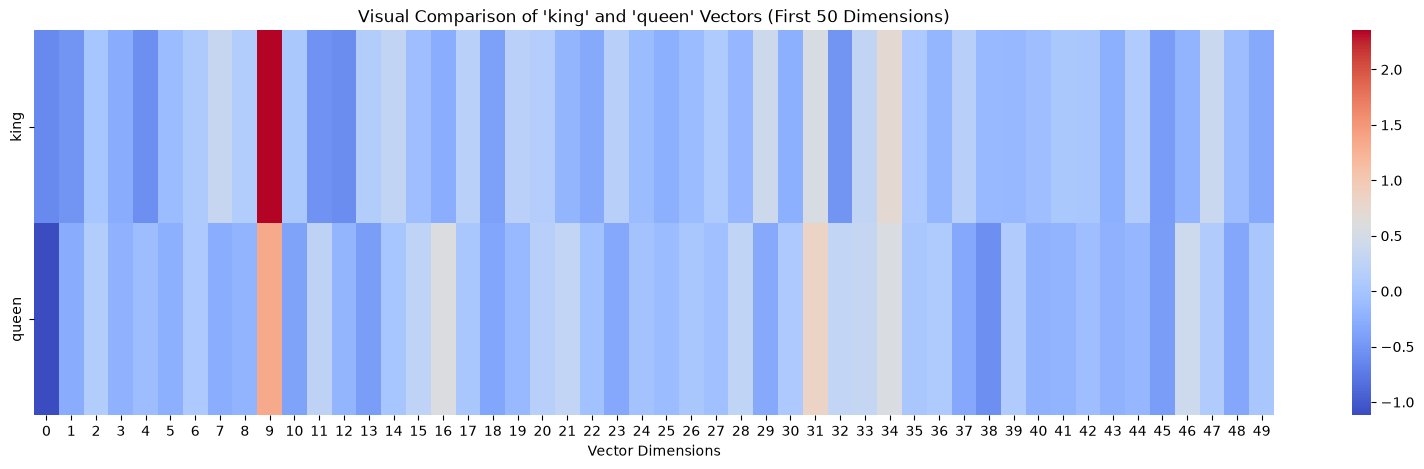

In [32]:
# visualize the vectors for cosine similarity
# for king and queen
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Get vectors
v1 = nlp("king").vector
v2 = nlp("queen").vector

# We will stack them and plot a slice of the 300 dimensions (e.g., the first 50) for clear visualization
vectors_matrix = np.vstack([v1[:50], v2[:50]])

plt.figure(figsize=(20, 5))
sns.heatmap(vectors_matrix, cmap="coolwarm", xticklabels=True, yticklabels=["king", "queen"])
plt.title("Visual Comparison of 'king' and 'queen' Vectors (First 50 Dimensions)")
plt.xlabel("Vector Dimensions")
plt.show()

In [33]:
# find what is in dimensions number 9 of the vector embedding
# Let's inspect the exact values at index 9 for all our words to see how they align
for w in words:
    val = nlp(w).vector[9]
    print(f"{w:<10} value at index 9: {val:.4f}")

print("\nMost similar pairs (excluding self-similarity):")
pairs = []
for i in range(len(words)):
    for j in range(i + 1, len(words)):
        w1, w2 = words[i], words[j]
        sim = nlp(w1).similarity(nlp(w2))
        pairs.append((sim, w1, w2))

# Sort by similarity descending
pairs.sort(reverse=True)
for sim, w1, w2 in pairs[:5]:
    print(f"{w1} and {w2}: {sim:.4f}")

NameError: name 'words' is not defined